# **Section 4 – Diabetes: Data Preparation, EDA, Inferential Statistics & Outlier Detection**

**PROG8245 – Lab 2: Tidying, Cleaning, Imputation, and Outlier Detection**

This notebook takes a raw diabetes dataset all the way from a cloud database to a statistically tested answer:

| Part | What happens | Why it matters |
|---|---|---|
| **0. Setup & Neon** | Load the data from a Neon PostgreSQL database into pandas | Real projects read data from databases, not loose files |
| **1. Data Preparation** | Clean, validate, and engineer features | Every later result is only as good as this foundation |
| **2. EDA** | Visualise distributions and relationships | Understand the data *before* testing anything |
| **3. Inferential Statistics** | Normality checks (Q-Q + Shapiro-Wilk) → t-tests | Decide whether differences are real or just chance |
| **4. Outlier Detection** | Lab tasks 4.1 – 4.8: box plot, scatter, Z-score, IQR, treatment | Check how extreme values affect our conclusions |

All reusable logic lives in classes inside [`src/diabetes_dataset/`](../src/diabetes_dataset/) so this notebook stays readable. Each class is explained the first time it is used.

## **The Research Question**

> **Do diabetic patients have significantly higher blood glucose, BMI, and systolic blood pressure than non-diabetic patients — and does that conclusion still hold once outliers are taken into account?**

Why these three measurements?

- **Glucose** – high blood sugar is the defining feature of diabetes, so we expect a large difference. It is a good "sanity check" for our method.
- **BMI** – excess body weight is one of the best-known risk factors for type 2 diabetes.
- **Systolic blood pressure** – hypertension and diabetes frequently occur together.

Every part of the notebook feeds this question: **preparation** makes the measurements trustworthy, **EDA** gives us a first look at the group differences, **inferential statistics** tests them formally, and **outlier detection** checks whether a handful of extreme values are driving the result.

### A note about the dataset

The lab handout describes the 768-row *Pima Indians Diabetes* file. This notebook uses **`data/diabetes_dataset.csv`** instead: **5,288 patients × 15 columns**, with readings such as age, gender, pulse rate, blood pressure, glucose (in **mmol/L**), height, weight, BMI, family history flags, and a `diabetic` (Yes/No) outcome.

All Section 4 techniques (box plots, scatter plots, Z-scores, IQR, treatment) apply exactly the same way. Only the column names are different.

---
# **Part 0 – Setup**

## 0.1 Imports

- **pandas / numpy** – tables and maths
- **matplotlib / seaborn** – charts
- **scipy.stats** – statistical tests
- **`diabetes_dataset`** – *our own* package in `src/`. Python only finds it if the `src` folder is on its search path (`sys.path`), so we add it first.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project root whether Jupyter was started in the project folder or in notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from diabetes_dataset import (
    NeonDatabase,
    DiabetesDataPreparer,
    EDAVisualizer,
    NormalityChecker,
    GroupComparison,
    OutlierDetector,
    format_p_values,
)
from diabetes_dataset.config import (
    RAW_CSV_PATH,
    RAW_TABLE_NAME,
    ENV_VAR_NAME,
    NUMERIC_FEATURES,
    ANALYSIS_FEATURES,
    TARGET,
    ALPHA,
    Z_THRESHOLD,
    IQR_MULTIPLIER,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
%matplotlib inline

print("Project root:", PROJECT_ROOT)
print("Raw CSV     :", RAW_CSV_PATH.relative_to(PROJECT_ROOT))

Project root: /Users/namy/Desktop/SCHOOL/Machine Learning Programming/PROG8245-Lab2-Tidying_Cleaning_Imputation_Outlier-Detection
Raw CSV     : data/diabetes_dataset.csv


## 0.2 Load the data from Neon

**Neon** is a cloud-hosted PostgreSQL database. The workflow is:

```text
data/diabetes_dataset.csv ──one-time upload script──▶ Neon table "diabetes_raw" ──SELECT … ORDER BY row_id──▶ pandas DataFrame
```

### Where does the password go?
The connection string contains your username and password, so it must **never** be written into the notebook or committed to GitHub. It lives in a file called **`.env`** in the project root:

```text
NEON_DATABASE_URL=postgresql://<user>:<password>@<host>/<database>?sslmode=require
```

`.env` is already listed in `.gitignore`, so Git ignores it. The `python-dotenv` package reads the file and exposes the value as an *environment variable*.

### The `NeonDatabase` class ([database.py](../src/common/database.py))

| Method | What it does |
|---|---|
| `NeonDatabase.from_env()` | Reads `.env` and opens a connection (a SQLAlchemy *engine*) |
| `test_connection()` | Runs `SELECT version()` to prove we are connected |
| `read_ordered(table)` | Runs `SELECT * FROM table ORDER BY row_id` and returns a DataFrame with `pd.read_sql()`, in the CSV's original row order |
| `list_tables()` | Lists the tables in the database |

**The notebook only reads.** The CSV is loaded into Neon once with `PYTHONPATH=src python -m diabetes_dataset.upload` (run from the project root). The script stores a `row_id` so the original row order can be restored, replaces the table if it already exists, and verifies the Neon copy matches the CSV. Because the notebook never writes, it works with a read-only database login.

> **Fallback:** until you paste a real connection string into `.env`, the cell below prints a warning and reads the CSV directly so the rest of the notebook still runs.

In [2]:
connection_string = NeonDatabase.read_connection_string()

if connection_string:
    db = NeonDatabase(connection_string)
    print("Connected to:", db.test_connection()[:60], "...")

    print("Tables in database:", db.list_tables())

    # Read the table in its original row order (it is uploaded once by diabetes_dataset.upload)
    raw_df = db.read_ordered(RAW_TABLE_NAME)
    data_source = f"Neon table '{RAW_TABLE_NAME}'"
    db.close()
else:
    print(f"WARNING: {ENV_VAR_NAME} is not set in .env - reading the local CSV instead of Neon.")
    raw_df = pd.read_csv(RAW_CSV_PATH)
    data_source = "local CSV (fallback)"

print(f"\nLoaded {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns from {data_source}")

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...
Tables in database: ['npors25_raw', 'employees', 'ontario_housing', 'car_details_raw', 'npors23_raw', 'npors24_raw', 'npors_value_labels', 'billboard_hot100_raw', 'billboard_audio_features_raw', 'diabetes_raw']



Loaded 5,288 rows x 15 columns from Neon table 'diabetes_raw'


---
# **Part 1 – Data Preparation Pipeline**

Before any chart or test we need a **clean foundation**. The `DiabetesDataPreparer` class ([preprocessing.py](../src/diabetes_dataset/preprocessing.py)) breaks the work into small steps:

| Step | Method | Purpose |
|---|---|---|
| 1 | `standardise_columns()` | Consistent lowercase `snake_case` column names |
| 2 | `clean_categoricals()` | Trim/case-fix text so `"female "` and `"Female"` are one category |
| 3 | `enforce_dtypes()` | Make numbers numeric and Yes/No flags small integers |
| 4 | `remove_duplicates()` | Drop exact duplicate rows |
| 5 | `remove_implausible_rows()` | Drop physiologically **impossible** values (data errors) |
| 6 | `drop_missing()` | Drop anything still missing |
| 7 | `engineer_features()` | Add new, more useful columns |

Each step records rows before/after in a log, and the class always works on a **copy**, so `raw_df` stays untouched as our baseline.

## 1.1 First look at the raw data

In [3]:
print("Shape:", raw_df.shape)
display(raw_df.head())

Shape: (5288, 15)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,1.65,70.2,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,1.47,42.5,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,1.52,47.0,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,1.63,57.4,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,1.42,36.0,17.79,0,0,0,0,0,No


In [4]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5288 entries, 0 to 5287
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5288 non-null   int64  
 1   gender                  5288 non-null   str    
 2   pulse_rate              5288 non-null   int64  
 3   systolic_bp             5288 non-null   int64  
 4   diastolic_bp            5288 non-null   int64  
 5   glucose                 5288 non-null   float64
 6   height                  5288 non-null   float64
 7   weight                  5288 non-null   float64
 8   bmi                     5288 non-null   float64
 9   family_diabetes         5288 non-null   int64  
 10  hypertensive            5288 non-null   int64  
 11  family_hypertension     5288 non-null   int64  
 12  cardiovascular_disease  5288 non-null   int64  
 13  stroke                  5288 non-null   int64  
 14  diabetic                5288 non-null   str    
dty

**What we see:** 15 columns, no obvious text-vs-number problems. `gender` and `diabetic` are text; the five history columns (`family_diabetes`, `hypertensive`, …) are 0/1 flags; the rest are measurements.

## 1.2 Data-quality report

`quality_report()` builds one table with each column's data type, missing values, number of unique values, and number of zeros. Zeros matter because in medical data a zero often means "not measured" rather than a real reading.

In [5]:
preparer = DiabetesDataPreparer(raw_df)
display(preparer.quality_report())
print("Duplicate rows:", raw_df.duplicated().sum())

,dtype,missing,missing_%,unique,zeros
age,int64,0,0.0,60,0
gender,str,0,0.0,2,0
pulse_rate,int64,0,0.0,91,0
systolic_bp,int64,0,0.0,136,0
diastolic_bp,int64,0,0.0,73,0
glucose,float64,0,0.0,937,1
height,float64,0,0.0,54,0
weight,float64,0,0.0,509,0
bmi,float64,0,0.0,1370,0
family_diabetes,int64,0,0.0,2,5119


Duplicate rows: 0


**Interpretation**

- **No missing values (NaN)** and **no duplicate rows**.
- Zeros in the 0/1 flag columns are expected (0 = "no").
- One patient has **glucose = 0**. That is impossible for a living person, so a clean-looking file can still hide bad values. That is why we run the next check.

## 1.3 Checking for impossible values

`describe()` shows the minimum and maximum of every measurement. Extremes that can't happen in a real patient show up quickly here.

In [6]:
display(raw_df[NUMERIC_FEATURES].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,5288.0,45.75,13.42,21.00,35.00,45.00,55.00,80.00
pulse_rate,5288.0,76.63,12.23,5.00,69.00,76.00,84.00,133.00
systolic_bp,5288.0,134.00,22.23,62.00,119.00,130.00,147.00,231.00
diastolic_bp,5288.0,82.23,12.48,45.00,73.00,81.00,90.00,119.00
glucose,5288.0,7.56,2.94,0.00,6.00,6.93,8.13,33.46
height,5288.0,1.55,0.08,0.36,1.52,1.55,1.60,1.96
weight,5288.0,53.64,10.08,3.00,46.78,53.00,59.90,100.70
bmi,5288.0,22.47,8.82,1.22,19.62,21.87,24.47,574.13


Several minimums and maximums are physically impossible:

- **height 0.36 m** and **BMI 574** (the world-record BMI is around 200)
- **weight 3 kg** for an adult
- **pulse 5 beats/min**
- **glucose 0 – 1.9 mmol/L** (below about 2 mmol/L a patient would be unconscious)

These are **data errors** such as typos, wrong units, or a sensor fault. They are not genuine extreme patients. `implausible_value_report()` checks every column against the medically plausible ranges stored in [config.py](../src/diabetes_dataset/config.py) (`PLAUSIBLE_RANGES`).

In [7]:
display(preparer.implausible_value_report())

invalid_rows = raw_df[preparer.invalid_row_mask()]
print(f"Rows with at least one impossible value: {len(invalid_rows)} "
      f"({len(invalid_rows) / len(raw_df):.2%} of the data)")
print("\nOutcome of those rows:")
print(invalid_rows[TARGET].value_counts())
display(invalid_rows.head(10))

,allowed_min,allowed_max,observed_min,observed_max,below_min,above_max,total_invalid
feature,,,,,,,
age,18.0,110.0,21.00,80.00,0,0,0
pulse_rate,30.0,220.0,5.00,133.00,3,0,3
systolic_bp,60.0,260.0,62.00,231.00,0,0,0
diastolic_bp,30.0,160.0,45.00,119.00,0,0,0
glucose,2.0,40.0,0.00,33.46,26,0,26
height,1.0,2.3,0.36,1.96,3,0,3
weight,25.0,300.0,3.00,100.70,4,0,4
bmi,10.0,80.0,1.22,574.13,2,2,4


Rows with at least one impossible value: 35 (0.66% of the data)

Outcome of those rows:
diabetic
No     34
Yes     1
Name: count, dtype: int64


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
152,24,Male,63,165,89,4.89,0.36,72.6,574.13,0,0,0,0,0,No
157,32,Male,77,106,73,1.17,1.60,52.1,20.35,0,0,0,0,0,No
613,44,Female,81,114,72,1.61,1.37,55.8,29.66,0,0,0,0,0,No
680,55,Male,77,123,91,0.89,1.63,62.7,23.73,0,0,0,0,0,No
718,36,Female,68,140,96,1.09,1.50,46.5,20.71,0,0,0,0,0,No
726,25,Female,88,145,91,0.43,1.50,42.0,18.70,0,0,0,0,0,No
885,75,Female,71,200,89,7.24,0.64,62.8,155.74,0,1,0,0,0,No
1138,28,Female,98,181,92,0.00,1.52,55.0,23.81,0,0,0,0,0,No
1279,46,Female,104,100,59,12.00,1.57,3.0,1.22,0,0,0,0,0,No
1308,50,Female,89,130,89,0.84,1.52,54.1,23.29,0,0,0,0,0,No


### Decision: drop the impossible rows (do not impute)

- They are **errors, not outliers**. A value that cannot exist tells us nothing about real patients.
- There are only **35 rows (0.66 %)**, so very little information is lost.
- **Imputing** them (for example, with the median, as in Section 3) would put made-up values into the exact columns we are about to test. That would artificially shrink the spread and could bias the t-tests.
- Only **one** of the 35 is diabetic, so dropping them barely changes the class balance.

> **Errors vs. outliers:** in this notebook, Part 1 removes values that are *impossible*. Section 4 deals with values that are *possible but unusual* (statistical outliers). Those are kept unless there is a clear reason to remove them.

## 1.4 Feature engineering

`engineer_features()` adds columns that make the data easier to analyse:

| New column | How it is built | Why |
|---|---|---|
| `diabetic_flag` | `1` if diabetic = "Yes", else `0` | The mean of a 0/1 column is a rate ("% diabetic") |
| `bmi` (recalculated) | weight ÷ height² | Guarantees BMI matches height and weight |
| `pulse_pressure` | systolic − diastolic | Marker of arterial stiffness |
| `age_group` | `pd.cut` into decades | Trends are easier to read in bands |
| `bmi_category` | WHO cut-offs 18.5 / 25 / 30 | Underweight / Normal / Overweight / Obese |
| `bp_category` | ACC/AHA cut-offs | Normal / Elevated / Stage 1 / Stage 2 |

## 1.5 Run the full pipeline

`run()` calls every step in order. This is called **method chaining**: each method returns the object itself (`return self`), so the calls can be written one after another.

In [8]:
preparer = DiabetesDataPreparer(raw_df)
df = preparer.run()

display(preparer.summary())
print("Clean shape:", df.shape)
display(df.head())

,step,rows_before,rows_after,rows_removed
0,standardise column names,5288,5288,0
1,"clean text categories (gender, diabetic)",5288,5288,0
2,enforce data types,5288,5288,0
3,remove duplicate rows (0 found),5288,5288,0
4,remove rows with impossible values (35 rows),5288,5253,35
5,drop rows with missing values (0 rows),5253,5253,0
6,"engineer features (diabetic_flag, bmi, pulse_p...",5253,5253,0


Clean shape: (5253, 20)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic,diabetic_flag,pulse_pressure,age_group,bmi_category,bp_category
0,42,Female,66,110,73,5.88,1.65,70.2,25.79,0,0,0,0,0,No,0,37,40-49,Overweight,Normal
1,35,Female,60,125,68,5.71,1.47,42.5,19.67,0,0,0,0,0,No,0,57,30-39,Normal,Elevated
2,62,Female,57,127,74,6.85,1.52,47.0,20.34,0,0,0,0,0,No,0,53,60-69,Normal,Elevated
3,73,Male,55,193,112,6.28,1.63,57.4,21.60,0,0,0,0,0,No,0,81,70+,Normal,Stage 2
4,68,Female,71,150,81,5.71,1.42,36.0,17.85,0,0,0,0,0,No,0,69,60-69,Underweight,Stage 2


## 1.6 Validate the cleaned data

**Assertions** are automatic checks. If any condition is false, the cell stops with an error. They protect the analysis from silently running on bad data if the source ever changes.

In [9]:
assert df.isna().sum().sum() == 0, "There should be no missing values"
assert df.duplicated().sum() == 0, "There should be no duplicate rows"
assert (df["systolic_bp"] > df["diastolic_bp"]).all(), "Systolic must exceed diastolic"
assert set(df[TARGET].unique()) == {"Yes", "No"}, "Target must be Yes/No"
assert len(raw_df) == 5288, "raw_df must be unchanged (baseline)"

print("All validation checks passed.")
print(f"Rows: {len(raw_df):,} raw  ->  {len(df):,} clean  ({len(raw_df) - len(df)} removed)")
print(df[TARGET].value_counts())
display(df[["bmi_category", "bp_category", "age_group"]].describe())

All validation checks passed.
Rows: 5,288 raw  ->  5,253 clean  (35 removed)
diabetic
No     4912
Yes     341
Name: count, dtype: int64


,bmi_category,bp_category,age_group
count,5253,5253,5253
unique,4,4,6
top,Normal,Stage 2,30-39
freq,3330,2120,1521


---
# **Part 2 – Exploratory Data Analysis (EDA)**

EDA means *looking* at the data before testing it. The `EDAVisualizer` class ([eda.py](../src/diabetes_dataset/eda.py)) provides one method per chart, and each method returns its figure.

## 2.1 How balanced is the outcome?

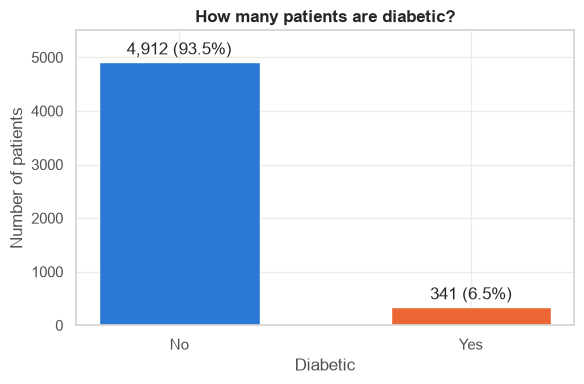

In [10]:
eda = EDAVisualizer(df)
eda.plot_target_balance()
plt.show()

Only **about 6.5 %** of patients are diabetic (341 vs 4,912). This **class imbalance** matters for two reasons:

1. The two groups have very different sizes, so later we use **Welch's t-test**, which does not assume equal group sizes or variances.
2. Any outlier rule that removes many diabetic patients could wipe out a large share of a small group. We check this in Section 4.

## 2.2 Distribution of each measurement

A **histogram** counts how many patients fall into each value range, and the smooth line (KDE) traces its shape. **Skewness** gives the shape as a number:

- **≈ 0** → symmetric (bell-shaped)
- **> 0** → long tail to the right (a few very high values)
- **< 0** → long tail to the left

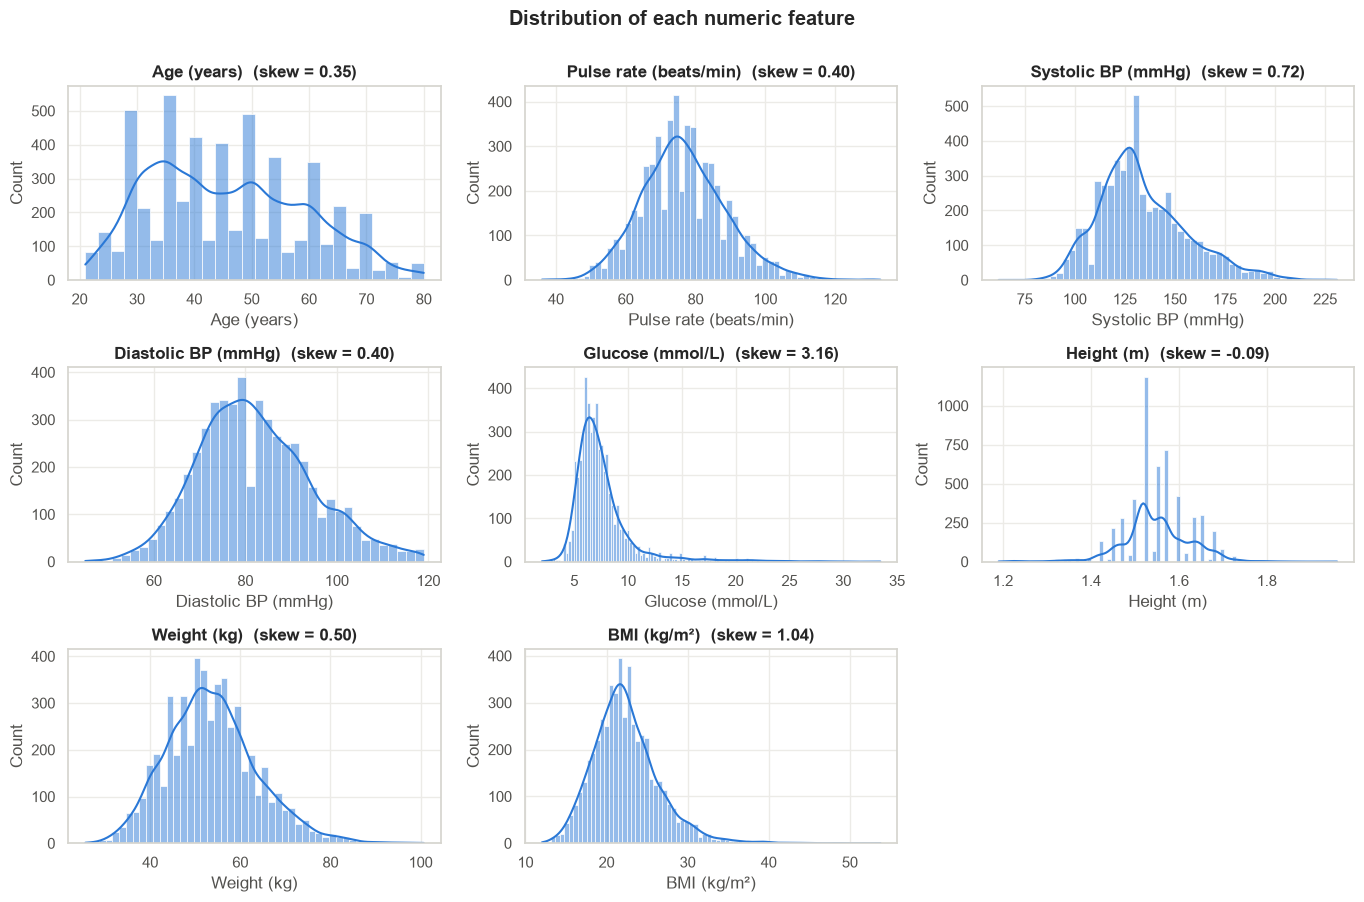

In [11]:
eda.plot_distributions(NUMERIC_FEATURES)
plt.show()

**Observations**

- **Glucose** is strongly **right-skewed** (skew ≈ 3). Most patients sit around 5–9 mmol/L, with a long tail up past 30.
- **BMI** is moderately right-skewed (≈ 1).
- **Age, blood pressure, height, and weight** are fairly symmetric.
- None of the measurements is perfectly bell-shaped. We return to this in the formal normality checks in Part 3.

## 2.3 Do the groups look different?

A **box plot** per group lets us compare medians and spreads side by side.

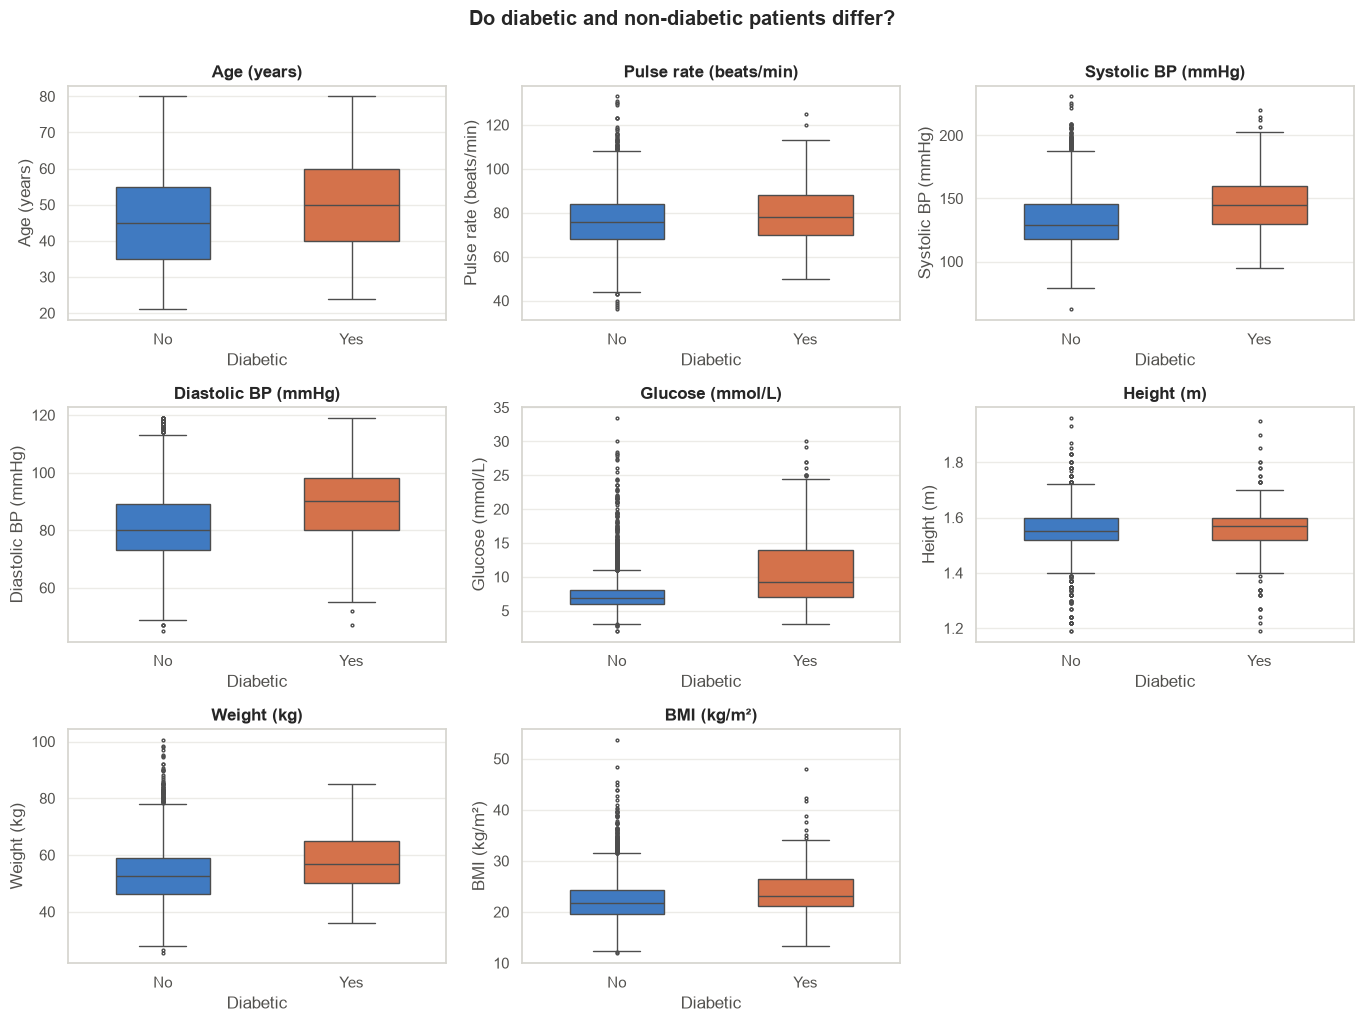

Summary of the three research-question features by group:


diabetic                No     Yes
glucose     mean      7.36   11.01
            median    6.86    9.28
            std       2.47    5.39
bmi         mean     22.27   23.89
            median   21.83   23.19
            std       4.05    4.46
systolic_bp mean    133.05  147.04
            median  129.00  145.00
            std      21.90   22.63

In [12]:
eda.plot_by_target(NUMERIC_FEATURES)
plt.show()

print("Summary of the three research-question features by group:")
display(eda.group_summary(ANALYSIS_FEATURES))

**Observations relevant to the research question**

- **Glucose:** the diabetic group's median is clearly higher (≈ 9.3 vs 6.9 mmol/L), and their spread is about twice as large.
- **Systolic BP:** diabetic patients are about **14 mmHg higher** on average.
- **BMI:** diabetic patients are higher, but only by about **1.6 kg/m²**, and the boxes overlap heavily.
- **Age** is also higher in the diabetic group, which is expected since type 2 diabetes becomes more common with age.

These are only *visual* differences. Part 3 tests whether they are bigger than random chance would produce.

## 2.4 Relationships between measurements

A **correlation heatmap** shows the Pearson correlation *r* between each pair of features (−1 = perfect negative, 0 = none, +1 = perfect positive).

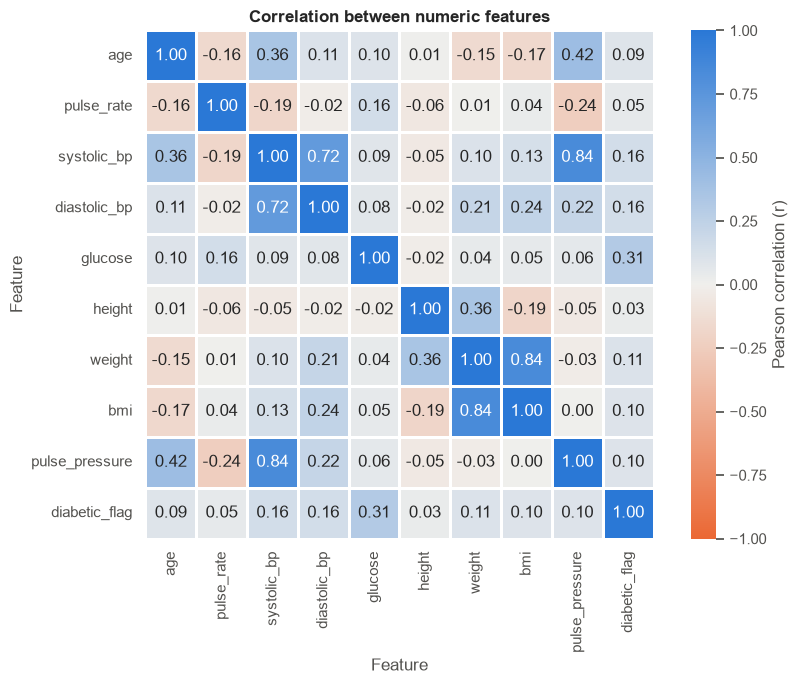

In [13]:
eda.plot_correlation_heatmap(NUMERIC_FEATURES + ["pulse_pressure", "diabetic_flag"])
plt.show()

**Observations**

- **Systolic & diastolic BP** are strongly correlated, as expected.
- **Weight ↔ BMI** is strongly correlated, because BMI is calculated from weight.
- **Glucose** has by far the strongest correlation with `diabetic_flag` (r ≈ 0.31), followed by **systolic and diastolic BP** (r ≈ 0.16).
- **BMI**'s correlation with `diabetic_flag` is weak (r ≈ 0.10). This suggests BMI will show the smallest group difference.
- All correlations with the outcome are modest. No single measurement separates the groups on its own.

## 2.5 Diabetes rate across engineered categories

The engineered features let us see how the **rate** of diabetes changes across groups.

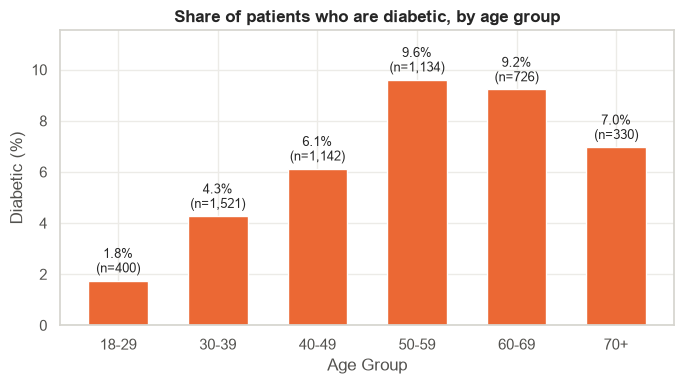

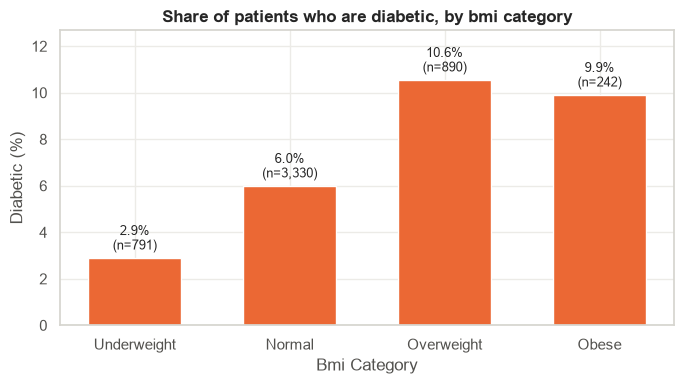

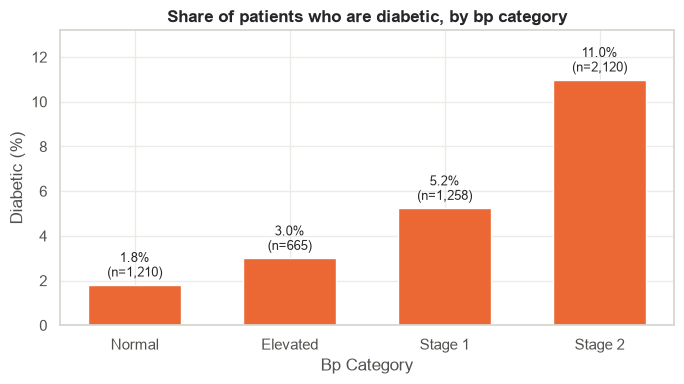

In [14]:
eda.plot_rate_by_category("age_group")
plt.show()
eda.plot_rate_by_category("bmi_category")
plt.show()
eda.plot_rate_by_category("bp_category")
plt.show()

**Observations**

- The diabetes rate rises from about **2 % in 18–29-year-olds to roughly 10 % at 50–59**.
- **Overweight/Obese** patients have more than **3× the rate** of underweight patients (about 10 % vs 3 %).
- The rate climbs steadily across blood-pressure categories, from about **2 % (Normal) to 11 % (Stage 2)**, which fits the known link between hypertension and diabetes.

**EDA conclusion:** all three research-question measurements *look* higher in diabetic patients. The next step is to test this formally.

---
# **Part 3 – Inferential Statistics**

EDA describes **this sample**. Inferential statistics asks whether what we see would hold for the **wider population**, or whether it could be random variation.

## 3.0 The hypotheses

For each feature (glucose, BMI, systolic BP):

- **H₀ (null hypothesis):** mean(diabetic) = mean(non-diabetic). There is no real difference.
- **H₁ (alternative hypothesis):** mean(diabetic) ≠ mean(non-diabetic).
- **Significance level:** α = 0.05. If the p-value is below 0.05, we reject H₀.

> **What is a p-value?** It is the probability of seeing a difference at least this large *if H₀ were true*. A tiny p-value means the observed difference would be very surprising under "no real difference", so we reject H₀.

## 3.1 Why we check normality first

The **independent-samples t-test** assumes each group's values come from a roughly **normal** (bell-shaped) distribution. So before running any t-test we do two mandatory checks:

1. **Q-Q plot** – a visual check
2. **Shapiro-Wilk test** – a formal check

Both are run **separately for each group**, because the assumption applies to each group on its own. The `NormalityChecker` class ([hypothesis_tests.py](../src/diabetes_dataset/hypothesis_tests.py)) handles both.

## 3.2 Normality check 1 – Q-Q plots

A **Q-Q (quantile-quantile) plot** sorts the data and plots each value against where it *would* fall if the data were perfectly normal.

- Dots **on the straight line** → normal
- Dots **curving upward at the right end** → right skew / a heavy upper tail
- An **S-shape** → tails that are heavier or lighter than normal

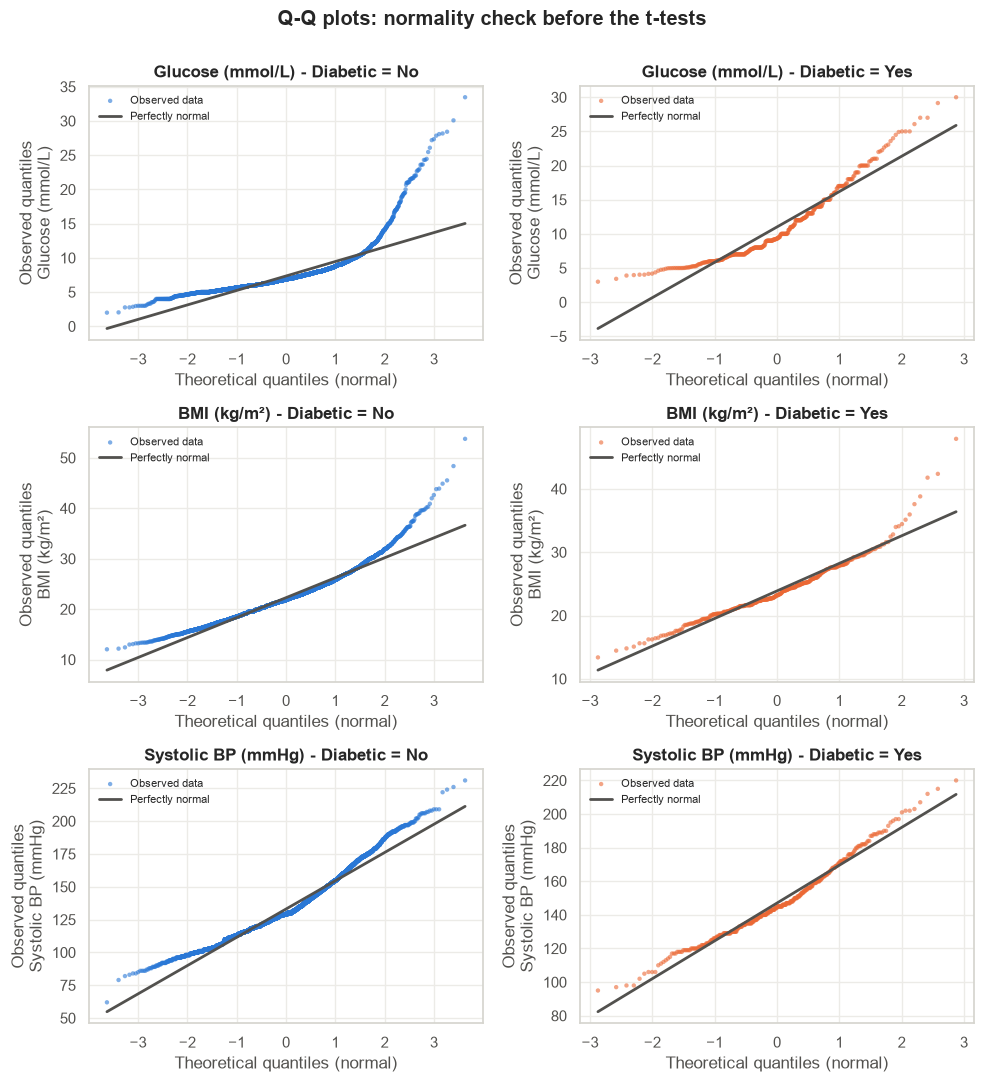

In [15]:
normality = NormalityChecker(df)
normality.plot_qq(ANALYSIS_FEATURES)
plt.show()

**Reading the Q-Q plots**

- **Glucose (both groups):** the dots bend sharply upward on the right, so the distribution is clearly **not normal** (heavy right tail). This is worst for non-diabetic patients.
- **BMI:** close to the line in the middle but curving up at the right, so it is **right-skewed**.
- **Systolic BP:** the closest to normal, with only mild departure at the ends.

## 3.3 Normality check 2 – Shapiro-Wilk test

- **H₀:** the data are normally distributed.
- **W** is close to 1 for normal data.
- **p < 0.05** → reject H₀ → **not normal**.

In [16]:
shapiro_results = normality.shapiro_wilk(ANALYSIS_FEATURES)
display(format_p_values(shapiro_results))

,feature,group,n,skewness,W,p_value,is_normal
0,glucose,No,4912,3.442,0.7287,4.22e-67,False
1,glucose,Yes,341,1.050,0.9094,1.94e-13,False
2,bmi,No,4912,1.031,0.9544,1.18e-36,False
3,bmi,Yes,341,1.134,0.9431,3.58e-10,False
4,systolic_bp,No,4912,0.737,0.9656,1.06e-32,False
5,systolic_bp,Yes,341,0.549,0.9774,3.42e-05,False


**Interpretation**

Every feature in every group has **p < 0.05**, so the Shapiro-Wilk test says *none* of them is perfectly normal. That matches the Q-Q plots.

**Does this mean we cannot use a t-test?** Not necessarily. Two points matter:

1. **Shapiro-Wilk is very sensitive with large samples.** With 4,912 non-diabetic patients, even a tiny, harmless departure from normality gives p < 0.05. This is why we always look at the Q-Q plot too.
2. **The Central Limit Theorem (CLT).** The t-test actually depends on the *sample mean* being normally distributed, not the raw values. The CLT says sample means become approximately normal as *n* grows, even if the raw data are skewed. With n = 341 and n = 4,912, both groups are large enough.

**Our plan, based on these checks:**

- Run **Welch's t-test**, which is valid here thanks to the CLT and does not assume equal variances.
- **Confirm** each result with the **Mann-Whitney U test**, a *non-parametric* test that makes no normality assumption at all.
- If both tests agree, the conclusion does not depend on the normality assumption.

## 3.4 Equal variances? Levene's test

The classic (Student's) t-test also assumes both groups have the same **variance** (spread). **Levene's test** checks this (H₀: the variances are equal). The `GroupComparison` class runs it alongside the t-tests.

## 3.5 Welch's t-tests, Mann-Whitney U, and effect sizes

For each feature, `GroupComparison.compare_all()` reports:

| Column | Meaning |
|---|---|
| `mean_Yes`, `mean_No`, `mean_diff` | Group means and the difference between them |
| `levene_p` | p < 0.05 → the variances differ → Welch's test is the right choice |
| `welch_t`, `welch_df`, `welch_p` | Welch's t-test result |
| `mannwhitney_p` | Non-parametric confirmation |
| `cohens_d` | **Effect size**: how *big* the difference is, in standard deviations (0.2 small, 0.5 medium, 0.8 large) |

In [17]:
comparison = GroupComparison(df, group_a="Yes", group_b="No")
ttest_results = comparison.compare_all(ANALYSIS_FEATURES)
display(format_p_values(ttest_results))

,mean_Yes,mean_No,mean_diff,levene_p,welch_t,welch_df,welch_p,mannwhitney_p,cohens_d,effect_size,significant
feature,,,,,,,,,,,
glucose,11.01,7.36,3.66,1.27e-101,12.443,350.0,1.11e-29,7.15e-42,1.327,large,True
bmi,23.89,22.27,1.61,4.82e-02,6.496,379.8,2.60e-10,1.64e-12,0.396,small,True
systolic_bp,147.04,133.05,13.99,2.78e-01,11.067,385.6,6.58e-25,6.42e-30,0.638,medium,True


## 3.6 Interpretation

| Feature | Difference (diabetic − not) | Welch p | Mann-Whitney p | Cohen's d | Verdict |
|---|---|---|---|---|---|
| **Glucose** | ≈ +3.7 mmol/L | ≪ 0.001 | ≪ 0.001 | ≈ 1.3 (**large**) | Significant |
| **Systolic BP** | ≈ +14 mmHg | ≪ 0.001 | ≪ 0.001 | ≈ 0.6 (**medium**) | Significant |
| **BMI** | ≈ +1.6 kg/m² | ≪ 0.001 | ≪ 0.001 | ≈ 0.4 (**small**) | Significant |

- For **all three** features we **reject H₀**: diabetic patients have significantly higher mean glucose, systolic BP, and BMI.
- **Mann-Whitney agrees every time**, so the non-normality found in 3.2–3.3 does not change the conclusion.
- **Significance is not the same as importance.** With 5,000+ patients even small differences become "significant". Cohen's d shows that the **glucose** difference is large, **blood pressure** is moderate, and **BMI** is real but small.

**Preliminary answer:** yes, all three are significantly higher in diabetic patients. Section 4 now checks the second half of the question: *does this still hold once outliers are dealt with?*

---
# **Section 4 – Outlier Detection (Diabetes Dataset)**

## **Learning Topic: Outlier Detection and Treatment**

An **outlier** is an observation that differs substantially from most of the data. Outliers can come from measurement errors, data-entry problems, unusual but legitimate cases, or genuinely rare events.

Outliers can distort means and standard deviations, correlations, regression coefficients, distance-based algorithms, scaling, and model evaluation.

**Important:** detecting an outlier does **not** automatically mean it should be deleted. Treatment has to be justified in the context of the data.

The `OutlierDetector` class ([outliers.py](../src/diabetes_dataset/outliers.py)) implements every method used below. It never changes the DataFrame it is given. Instead it returns **boolean masks** (a True/False table where `True` = potential outlier), which we can count, plot, or use to build a cleaned *copy*.

### **Task 4.1 – Load and Explore the Diabetes Dataset**

The data was loaded from Neon in Part 0 and cleaned in Part 1. Here we confirm what we are working with and choose the features to examine.

In [18]:
print("Data source:", data_source)
print("Raw shape  :", raw_df.shape, "  Clean shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values in clean data:", int(df.isna().sum().sum()))
print("Impossible values removed in Part 1:", len(raw_df) - len(df))

print("\nNumeric features examined for outliers:", NUMERIC_FEATURES)
display(df[NUMERIC_FEATURES].describe().T.round(2))

Data source: Neon table 'diabetes_raw'
Raw shape  : (5288, 15)   Clean shape: (5253, 20)

Columns: ['age', 'gender', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'height', 'weight', 'bmi', 'family_diabetes', 'hypertensive', 'family_hypertension', 'cardiovascular_disease', 'stroke', 'diabetic', 'diabetic_flag', 'pulse_pressure', 'age_group', 'bmi_category', 'bp_category']

Data types:
int64       5
Int8        5
float64     4
category    1
str         1
int8        1
category    1
category    1
category    1
Name: count, dtype: int64

Missing values in clean data: 0
Impossible values removed in Part 1: 35

Numeric features examined for outliers: ['age', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'height', 'weight', 'bmi']


,count,mean,std,min,25%,50%,75%,max
age,5253.0,45.73,13.41,21.00,35.00,45.00,55.00,80.00
pulse_rate,5253.0,76.67,12.11,36.00,69.00,76.00,84.00,133.00
systolic_bp,5253.0,133.96,22.22,62.00,119.00,130.00,147.00,231.00
diastolic_bp,5253.0,82.22,12.49,45.00,73.00,81.00,90.00,119.00
glucose,5253.0,7.59,2.90,2.00,6.00,6.94,8.14,33.46
height,5253.0,1.55,0.08,1.19,1.52,1.55,1.60,1.96
weight,5253.0,53.68,10.04,25.60,46.80,53.00,60.00,100.70
bmi,5253.0,22.38,4.09,12.04,19.65,21.89,24.46,53.77


**Which features, and why?** We examine all eight continuous measurements (`NUMERIC_FEATURES`). The 0/1 history flags are left out because a value can only be 0 or 1, so "extreme" has no meaning for them.

**Missing/invalid values:** there are no NaNs. The 35 impossible readings (glucose ≈ 0, height 0.36 m, BMI 574, pulse 5, …) were already removed in Part 1, so everything examined below is at least *physically possible*.

### **Task 4.2 – Box Plot Method**

How to read a box plot:

| Part | Meaning |
|---|---|
| **Box** | Middle 50 % of the data, from **Q1** (25th percentile) to **Q3** (75th percentile) |
| **Line inside the box** | **Median** (50th percentile) |
| **Box height** | **IQR** = Q3 − Q1 |
| **Whiskers** | Extend to the furthest point still within **1.5 × IQR** of the box |
| **Red dots** | Points beyond the whiskers → **potential outliers** |

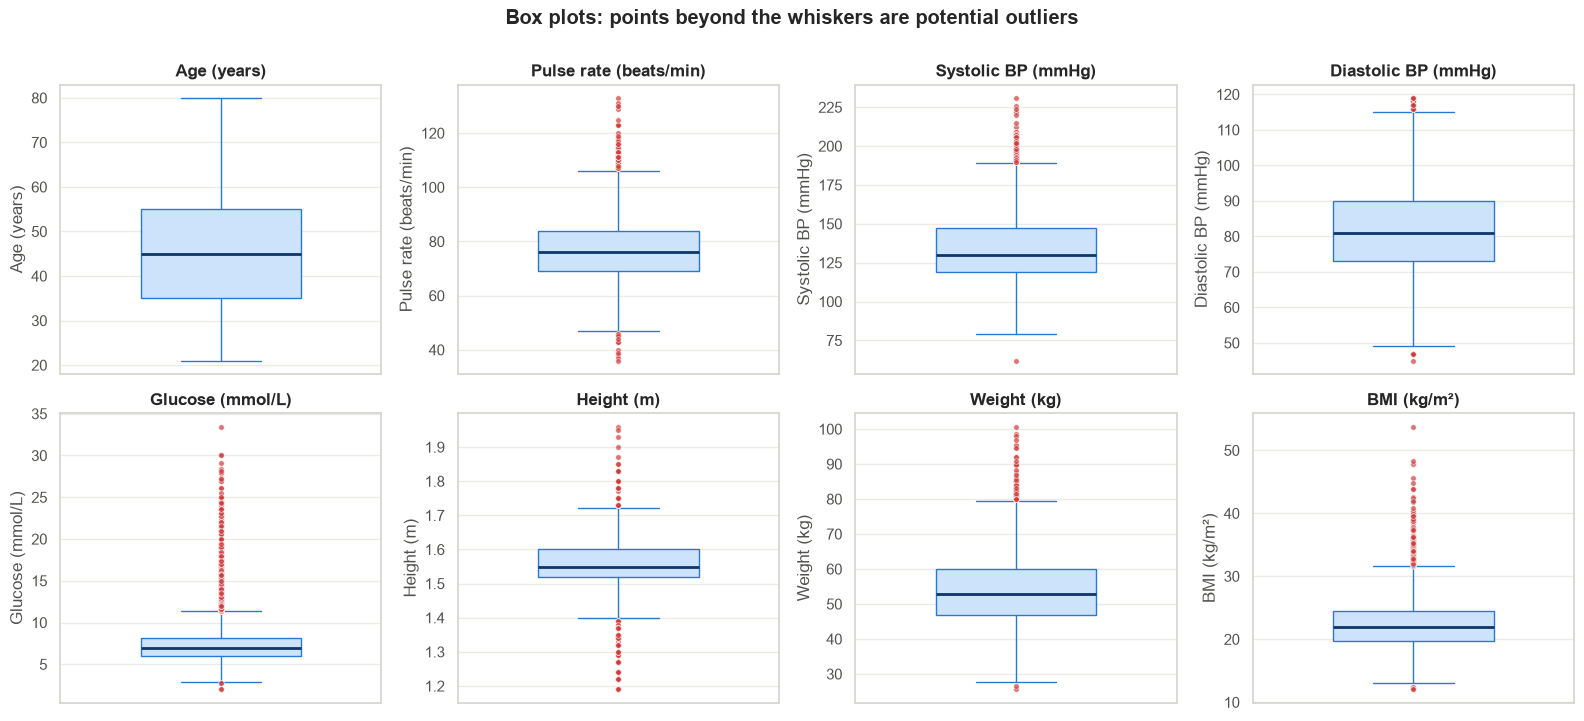

Points beyond the whiskers per feature:
glucose         366
height          186
bmi             132
systolic_bp     111
pulse_rate       93
weight           75
diastolic_bp     54
age               0
Name: box_plot, dtype: int64


In [19]:
detector = OutlierDetector(df, NUMERIC_FEATURES)
detector.plot_boxplots()
plt.show()

print("Points beyond the whiskers per feature:")
print(detector.boxplot_flier_counts().sort_values(ascending=False))

**Observations**

- **Glucose** has by far the most extreme values: a long column of red dots above about 11.4 mmol/L, all on the **high** side.
- **Height** has many points on *both* sides. Its IQR is very narrow (1.52–1.60 m), so even ordinary tall or short people fall outside the whiskers.
- **BMI, systolic BP, and pulse rate** have upper-tail outliers.
- **Age** has **no** outliers: every age from 21 to 80 is within the whiskers.

### **Task 4.3 – Scatter Plot Method**

A scatter plot shows **two** features at once, so it can reveal points that are unusual in *combination* even when neither value is extreme on its own.

**Glucose vs BMI** links our two main metabolic measurements. Points are coloured by diabetic status. Red rings mark values flagged by the Z-score rule (|z| > 3) on either axis, which is computed formally in Task 4.4.

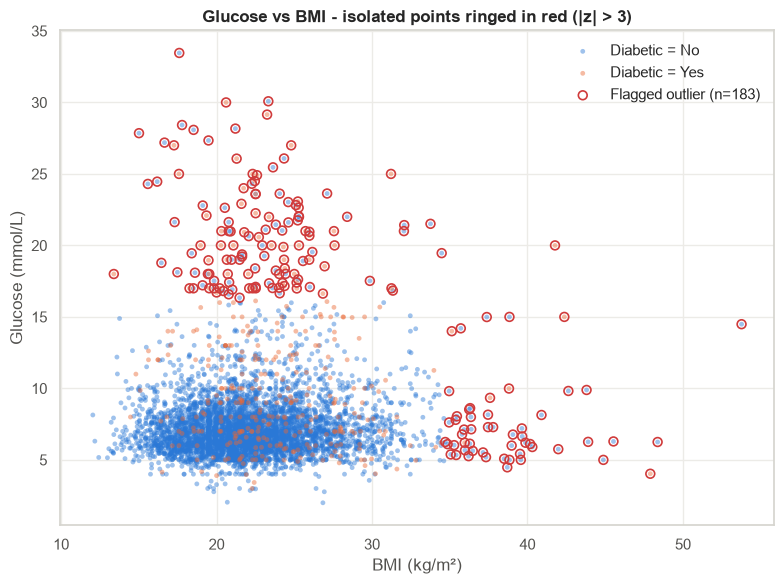

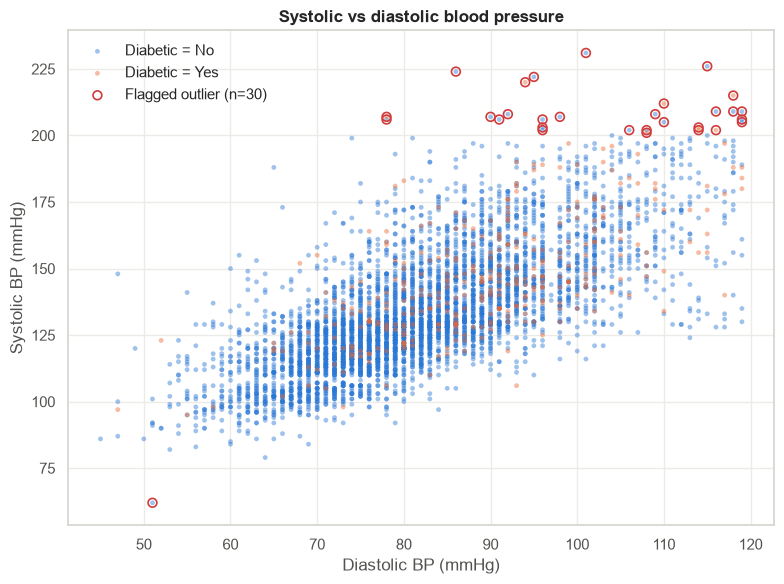

In [20]:
z_mask = detector.z_score_outliers()

detector.plot_scatter("bmi", "glucose", mask=z_mask,
                      title="Glucose vs BMI - isolated points ringed in red (|z| > 3)")
plt.show()

detector.plot_scatter("diastolic_bp", "systolic_bp", mask=z_mask,
                      title="Systolic vs diastolic blood pressure")
plt.show()

**Observations**

- **Glucose vs BMI:** the main cloud sits at BMI 15–30 and glucose 4–10. Two groups of points stand apart:
  - a **horizontal band of very high glucose** (above about 16 mmol/L) spread across all BMI values;
  - a few points with **very high BMI** (above about 35) and normal glucose.
- **Systolic vs diastolic:** the strong diagonal trend is clear. The most isolated points are at the top right (systolic above 200 mmHg).
- **Key insight:** diabetic (orange) patients are heavily **over-represented** in the high-glucose band. They make up only 6.5 % of the data but about **45 %** of the glucose Z-score outliers (58 of 129). These points carry the very signal our research question is about. The high-glucose *non-diabetic* patients are also plausible: they could be undiagnosed cases, or readings taken after a meal.

### **Task 4.4 – Z-Score Method**

$$ z = \frac{x - \mu}{\sigma} $$

A Z-score measures how many **standard deviations** a value is from the mean. With the conventional threshold **|z| > 3**, a value is flagged if it lies more than 3 SDs away. For truly normal data that happens to only about 0.3 % of observations.

First, step by step for **glucose** so the formula is visible:

In [21]:
glucose = df["glucose"]
mu = glucose.mean()
sigma = glucose.std(ddof=0)          # population standard deviation, matching the formula

z_glucose = (glucose - mu) / sigma
glucose_z_outliers = df[z_glucose.abs() > Z_THRESHOLD]

print(f"mean (mu)  = {mu:.3f}")
print(f"std (sigma) = {sigma:.3f}")
print(f"|z| > {Z_THRESHOLD} means glucose < {mu - Z_THRESHOLD * sigma:.2f} or > {mu + Z_THRESHOLD * sigma:.2f} mmol/L")
print(f"Glucose Z-score outliers: {len(glucose_z_outliers)}")
display(glucose_z_outliers[["age", "gender", "glucose", "bmi", TARGET]]
        .assign(z=z_glucose).sort_values("z", ascending=False).head(8))

mean (mu)  = 7.593
std (sigma) = 2.902
|z| > 3.0 means glucose < -1.11 or > 16.30 mmol/L
Glucose Z-score outliers: 129


,age,gender,glucose,bmi,diabetic,z
453,35,Female,33.46,17.60,No,8.914884
3468,40,Female,30.08,23.33,No,7.749997
3706,30,Female,30.00,20.61,Yes,7.722426
393,55,Male,29.15,23.25,Yes,7.429481
1925,70,Male,28.42,17.78,No,7.177893
4304,49,Female,28.17,21.21,No,7.091733
1155,35,Female,28.08,18.52,No,7.060715
1796,60,Female,27.85,15.01,No,6.981447


Now for every feature at once using the class (it applies the same formula to each column):

In [22]:
z_counts = detector.z_score_outliers().sum().rename("z_score_outliers")
print(f"Z-score outliers per feature (|z| > {Z_THRESHOLD}):")
print(z_counts.sort_values(ascending=False))
print(f"\nTotal flagged values: {z_counts.sum()}   |   "
      f"rows with at least one flag: {detector.z_score_outliers().any(axis=1).sum()}")

Z-score outliers per feature (|z| > 3.0):
glucose         129
height           55
bmi              55
weight           31
systolic_bp      30
pulse_rate       27
age               0
diastolic_bp      0
Name: z_score_outliers, dtype: int64

Total flagged values: 327   |   rows with at least one flag: 284


**Observations**

- **Glucose: 129** values flagged, all above about 16.3 mmol/L. There are none on the low side, because the skew means mean − 3σ is below zero.
- **Age and diastolic BP: 0**. Their distributions are compact and symmetric.
- **Caveat:** the Z-score uses the mean and SD, and both are *pulled up* by the outliers themselves. On skewed data (like glucose) this makes the rule less reliable, which is why we also use IQR.

### **Task 4.5 – Interquartile Range (IQR) Method**

$$ IQR = Q3 - Q1 $$

$$ Lower\ Bound = Q1 - 1.5(IQR) \qquad Upper\ Bound = Q3 + 1.5(IQR) $$

The IQR rule is built from **percentiles**, so extreme values do not affect the bounds. That makes it **robust** for skewed data.

Step by step for **glucose**:

In [23]:
q1 = df["glucose"].quantile(0.25)
q3 = df["glucose"].quantile(0.75)
iqr = q3 - q1
lower = q1 - IQR_MULTIPLIER * iqr
upper = q3 + IQR_MULTIPLIER * iqr

glucose_iqr_outliers = df[(df["glucose"] < lower) | (df["glucose"] > upper)]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Lower bound = {q1:.2f} - 1.5 x {iqr:.2f} = {lower:.2f}")
print(f"Upper bound = {q3:.2f} + 1.5 x {iqr:.2f} = {upper:.2f}")
print(f"Glucose IQR outliers: {len(glucose_iqr_outliers)}")

Q1 = 6.00, Q3 = 8.14, IQR = 2.14
Lower bound = 6.00 - 1.5 x 2.14 = 2.79
Upper bound = 8.14 + 1.5 x 2.14 = 11.35
Glucose IQR outliers: 366


For every feature, with the class:

In [24]:
display(detector.iqr_bounds().round(2))

iqr_mask = detector.iqr_outliers()
print("IQR outliers per feature:")
print(iqr_mask.sum().sort_values(ascending=False))
print(f"\nRows with at least one IQR flag: {iqr_mask.any(axis=1).sum()} of {len(df):,}")

,Q1,Q3,IQR,lower_bound,upper_bound,min,max
age,35.00,55.00,20.00,5.00,85.00,21.00,80.00
pulse_rate,69.00,84.00,15.00,46.50,106.50,36.00,133.00
systolic_bp,119.00,147.00,28.00,77.00,189.00,62.00,231.00
diastolic_bp,73.00,90.00,17.00,47.50,115.50,45.00,119.00
glucose,6.00,8.14,2.14,2.79,11.35,2.00,33.46
height,1.52,1.60,0.08,1.40,1.72,1.19,1.96
weight,46.80,60.00,13.20,27.00,79.80,25.60,100.70
bmi,19.65,24.46,4.81,12.43,31.68,12.04,53.77


IQR outliers per feature:
glucose         366
height          186
bmi             132
systolic_bp     111
pulse_rate       93
weight           75
diastolic_bp     54
age               0
dtype: int64

Rows with at least one IQR flag: 832 of 5,253


**Observations**

- **Glucose: 366** values above 11.35 mmol/L. That is nearly 3× as many as the Z-score method found.
- **Height: 186**. With a narrow IQR (0.08 m), anyone shorter than 1.40 m or taller than 1.72 m is flagged, even though these are normal adult heights.
- The IQR rule flags **more** values than the Z-score rule for every feature.

### **Task 4.6 – Compare Detection Methods**

,box_plot,z_score,iqr_rule,flagged_by_both,skewness,iqr_%
age,0,0,0,0,0.35,0.00
pulse_rate,93,27,93,27,0.40,1.77
systolic_bp,111,30,111,30,0.72,2.11
diastolic_bp,54,0,54,0,0.40,1.03
glucose,366,129,366,129,3.16,6.97
height,186,55,186,55,-0.09,3.54
weight,75,31,75,31,0.50,1.43
bmi,132,55,132,55,1.04,2.51


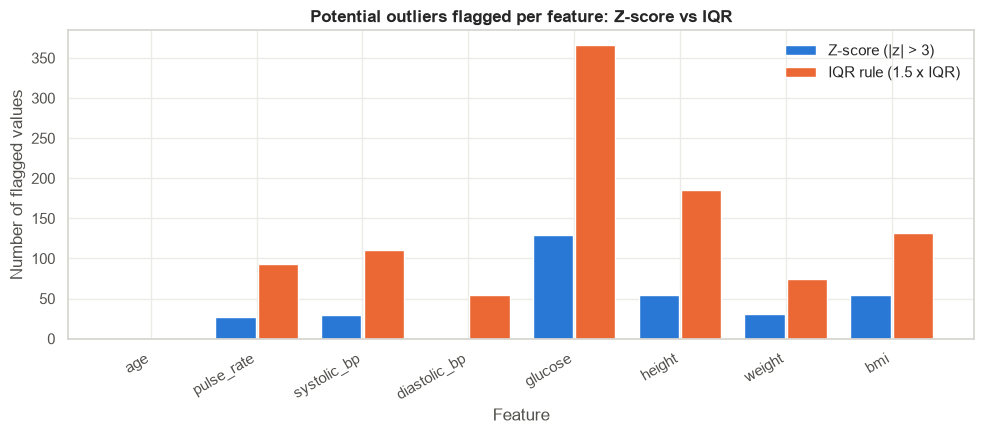

In [25]:
outlier_summary = detector.summary()
display(outlier_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(outlier_summary))
ax.bar(x - 0.2, outlier_summary["z_score"], width=0.38, color="#2a78d6", label="Z-score (|z| > 3)")
ax.bar(x + 0.2, outlier_summary["iqr_rule"], width=0.38, color="#eb6834", label="IQR rule (1.5 x IQR)")
ax.set_xticks(x, outlier_summary.index, rotation=30, ha="right")
ax.set(title="Potential outliers flagged per feature: Z-score vs IQR",
       xlabel="Feature", ylabel="Number of flagged values")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Why the methods disagree**

| | Box plot | IQR rule | Z-score |
|---|---|---|---|
| Based on | Quartiles (visual) | Quartiles (numeric) | Mean & SD |
| Affected by outliers? | No | No | **Yes**: outliers inflate the SD, which widens the bounds |
| Assumes normality? | No | No | **Yes**: "3 SD = rare" only holds for bell-shaped data |
| Best for | Spotting patterns | Skewed data | Roughly normal data |

1. **Box plot = IQR.** The counts match exactly because matplotlib draws whiskers using the same 1.5 × IQR rule. The box plot is the *picture* of the IQR rule.
2. **The Z-score always flags fewer.** For a normal distribution the IQR fences sit at about ±2.7 SD, which is tighter than ±3 SD. Also, outliers inflate σ, so the Z-score bounds stretch outwards, an effect called **masking**.
3. **The gap is biggest for skewed features.** For glucose (skew ≈ 3.2) the IQR rule flags 366 values and the Z-score flags 129. For near-symmetric features the two are closer.
4. **"Flagged by both"** equals the Z-score count for every feature, so every Z-score outlier is also an IQR outlier, but not the other way around.

Given that glucose and BMI are skewed (Part 2) and the Q-Q plots showed non-normal data (Part 3), **IQR is the more appropriate detector here**. Being *detected* is still not the same as deserving *removal*, though.

### **Task 4.7 – Treat Outliers Carefully**

#### Step 1 – Who are the outliers?
Before removing anything, check **which patients** each rule would delete.

In [26]:
by_group = detector.outliers_by_group(iqr_mask)
by_group["% of diabetic group"] = (by_group["Yes"] / (df[TARGET] == "Yes").sum() * 100).round(1)
print("IQR outliers split by diabetic status:")
display(by_group)

IQR outliers split by diabetic status:


diabetic,No,Yes,% of diabetic group
age,0,0,0.0
pulse_rate,81,12,3.5
systolic_bp,96,15,4.4
diastolic_bp,44,10,2.9
glucose,233,133,39.0
height,155,31,9.1
weight,68,7,2.1
bmi,120,12,3.5


**This is the critical finding.** Diabetic patients are only 6.5 % of the data but **36 %** of the glucose IQR outliers. Removing those outliers would delete **133 of the 341 diabetic patients (39 %)**. High glucose is *how diabetes is diagnosed*, so these values are **legitimate and highly informative**, not errors. Deleting them would remove much of the effect we are trying to measure and make the diabetic group look healthier than it really is.

#### Step 2 – Our documented treatment rule

| Feature | Decision | Justification |
|---|---|---|
| **Glucose** | **Keep** all values | Extreme glucose is the diagnostic signal of diabetes |
| **Age, height, weight, pulse, diastolic BP** | **Keep** | Values are plausible, and flagged heights are ordinary adult heights |
| **BMI, systolic BP** | **Remove rows with \|z\| > 3** | Rare, very extreme values (BMI ≈ 35+, SBP ≈ 200+) inflate the SD; they are not diagnostic criteria; the conservative Z rule removes far fewer rows than IQR |

We use the **Z-score rule (not IQR)** for treatment on purpose. The aim is to trim only the most *extreme* tail, not 2–3 % of every column. The cleaned data is a **copy**; `df` stays untouched as the baseline.

In [27]:
TREAT_FEATURES = ["bmi", "systolic_bp"]

df_treated = detector.remove(method="z_score", features=TREAT_FEATURES)   # returns a COPY

print(f"Rows before: {len(df):,}   after: {len(df_treated):,}   removed: {len(df) - len(df_treated)}")
print("\nDiabetic status of the treated data:")
print(df_treated[TARGET].value_counts())
assert len(df) == 5253, "Original df must not be modified"

Rows before: 5,253   after: 5,168   removed: 85

Diabetic status of the treated data:
diabetic
No     4842
Yes     326
Name: count, dtype: int64


#### Step 3 – Compare descriptive statistics before vs after

In [28]:
stats_comparison = OutlierDetector.compare_statistics(df, df_treated, ANALYSIS_FEATURES)
display(stats_comparison)

count            mean                   median            std                
              after  before   after  before change_%   after  before  after before change_%
glucose      5168.0  5253.0    7.59    7.59    -0.02    6.94    6.94   2.90   2.90    -0.09
bmi          5168.0  5253.0   22.20   22.38    -0.80   21.87   21.89   3.72   4.09    -9.08
systolic_bp  5168.0  5253.0  133.38  133.96    -0.43  130.00  130.00  21.45  22.22    -3.45

**Reading the table**

- **Means** move only slightly (well under 1 %).
- **Medians** barely change at all. The median is robust because it ignores how extreme the tails are.
- **Standard deviation** drops the most for **BMI** (about 9 %) and systolic BP (about 3.5 %). Removing just 85 rows (1.6 %) shows how much a handful of extreme values was inflating the spread.
- Glucose was not treated, so its tiny change comes only from the removed BMI/SBP rows.

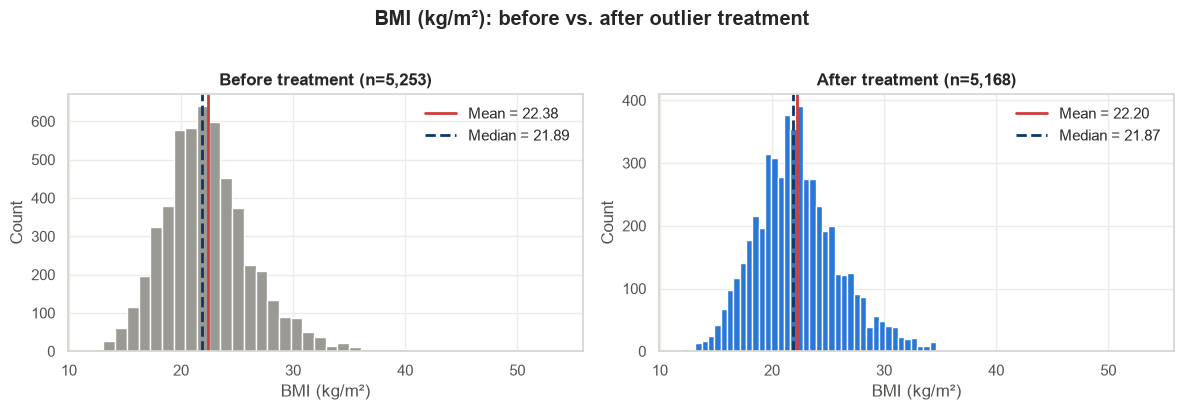

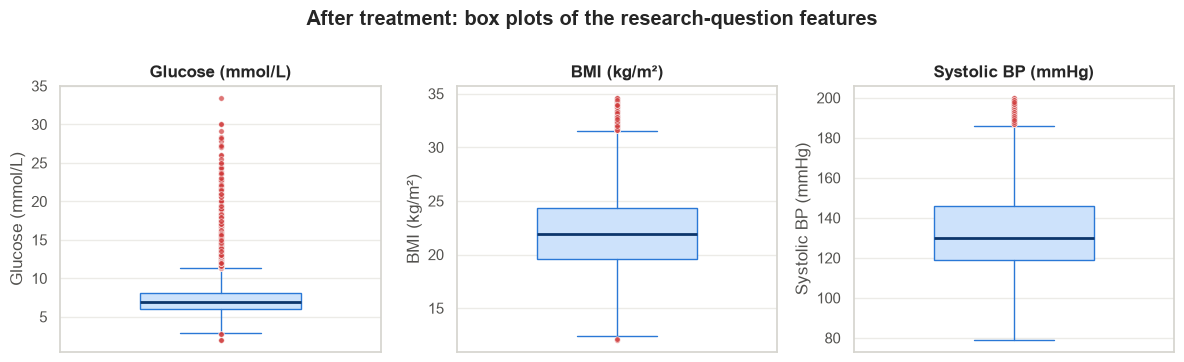

In [29]:
detector.plot_before_after(df_treated, "bmi")
plt.show()

OutlierDetector(df_treated, NUMERIC_FEATURES).plot_boxplots(
    features=ANALYSIS_FEATURES, ncols=3,
    title="After treatment: box plots of the research-question features")
plt.show()

The BMI histogram loses its thin right tail (values ≈ 35–54), and the mean moves slightly closer to the median. Glucose still shows its high tail, as intended.

#### Step 4 – Does our research conclusion survive the treatment? (sensitivity analysis)

This step answers the second half of the research question. We re-run the exact same tests on the treated data.

In [30]:
ttest_treated = GroupComparison(df_treated).compare_all(ANALYSIS_FEATURES)

sensitivity = pd.DataFrame({
    "cohens_d (original)": ttest_results["cohens_d"],
    "cohens_d (treated)": ttest_treated["cohens_d"],
    "welch_p (original)": ttest_results["welch_p"],
    "welch_p (treated)": ttest_treated["welch_p"],
    "significant (treated)": ttest_treated["significant"],
})
display(format_p_values(sensitivity))

,cohens_d (original),cohens_d (treated),welch_p (original),welch_p (treated),significant (treated)
feature,,,,,
glucose,1.327,1.349,1.11e-29,6.19e-29,True
bmi,0.396,0.378,2.60e-10,2.49e-10,True
systolic_bp,0.638,0.602,6.58e-25,7.41e-24,True


**Result:** after outlier treatment, all three differences remain **highly significant** and the effect sizes barely move. **The conclusion is robust**: it is not driven by a few extreme patients.

### **Task 4.8 – Diabetes Reflection**

> *Draft answers based on this notebook's output. Rewrite them in your own words before submitting.*

1. **What is an outlier?** An observation that lies far from most of the data, for example a glucose reading of 30 mmol/L when the typical range is 5–9.

2. **Three possible causes:** (a) measurement or sensor error; (b) data-entry mistakes such as typos or wrong units (height entered as 0.36 m); (c) genuine but rare cases, such as a patient with severe uncontrolled diabetes. Sampling from a different population can also produce outliers.

3. **Clearest visual outliers:** **glucose** (a long tail of high values), then **height**, **BMI**, and **systolic BP**. **Age** had none.

4. **Z-score (|z| > 3):** 327 flagged values in total (glucose 129, BMI 55, height 55, weight 31, systolic BP 30, pulse 27).

5. **IQR rule:** 1,017 flagged values in total (glucose 366, height 186, BMI 132, systolic BP 111, pulse 93, weight 75, diastolic BP 54).

6. **Why they differ:** the Z-score uses the mean and SD, which the outliers themselves inflate (masking), and it assumes normality. IQR uses quartiles, which outliers do not affect. On skewed data like glucose the IQR rule flags far more values.

7. **When to retain an outlier:** when it is plausible and meaningful. Here, high glucose *is* diabetes. Removing it would delete 39 % of diabetic patients and hide the effect we are studying.

8. **When removal is justified:** when a value is impossible (glucose 0, BMI 574, which we removed in Part 1), or when a rare extreme value distorts statistics without carrying meaning for the question, and the rule is documented and applied to a copy.

9. **Effect on descriptive statistics:** means and medians changed by less than 1 %. BMI's standard deviation fell by about 9 %, and systolic BP's by a few percent. The t-test conclusions and effect sizes stayed the same.

10. **Effect on a downstream ML model:** untreated outliers can pull regression coefficients towards them, dominate distance-based models (k-NN, k-means), distort `StandardScaler` (mean/SD), and inflate error metrics such as RMSE. Wrongly *removing* informative outliers is just as harmful: a diabetes classifier trained without high-glucose patients would miss the very cases it most needs to catch.

---
# **Answer to the Research Question**

> **Do diabetic patients have significantly higher blood glucose, BMI, and systolic blood pressure than non-diabetic patients, and does that conclusion still hold once outliers are taken into account?**

**Yes, on both counts.**

| Feature | Diabetic vs non-diabetic | Effect size | Survives outlier treatment? |
|---|---|---|---|
| Glucose | ≈ +3.7 mmol/L | **Large** (d ≈ 1.3) | ✅ |
| Systolic BP | ≈ +14 mmHg | **Medium** (d ≈ 0.6) | ✅ |
| BMI | ≈ +1.6 kg/m² | **Small** (d ≈ 0.4) | ✅ |

**How we got here**

1. **Preparation:** 35 physically impossible rows were removed, not imputed, because they were errors. Six interpretable features were engineered.
2. **EDA:** showed that all three measurements look higher in diabetic patients, and that glucose and BMI are right-skewed.
3. **Inferential statistics:** Q-Q plots and Shapiro-Wilk showed the data are not normal. With large samples (CLT), Welch's t-test is still valid, and the non-parametric Mann-Whitney U test confirmed every result.
4. **Outlier detection:** IQR suits these skewed features better than the Z-score. Most glucose "outliers" turned out to be diabetic patients, so they were kept. Trimming only extreme BMI/SBP values left the conclusion unchanged.

**Limitations**

- This is **observational** data. It shows *association*, not *causation*.
- Diabetic patients are also **older** on average. Age may explain part of the blood-pressure difference. A regression model controlling for age would be a natural next step.
- Glucose was measured at an unknown time (fasting vs random), which limits clinical interpretation.